# Amazon review-log analysis — ratings & verified purchases

This notebook analyses the raw Amazon interaction logs used by FlowRec and looks at:

1. **Rating distribution** — how the 1–5 star ratings are spread.
2. **`verified_purchase` distribution** — the share of verified vs. non-verified reviews.
3. **Joint distribution** — how the verified flag relates to the star rating.

**Data.** We read the "dataframe format" parquet logs in `data/raw/dataframe_format/`.
Three review logs are available; they use slightly different column names, which the
loader normalises to a common schema (`rating`, `verified`):

| dataset | rows | rating col | verified col | notes |
|---|---|---|---|---|
| `instruments_2018` | ~1.5 M | `overall` | `verified` | verified varies (default) |
| `beauty_2023` | ~24 M | `rating` | `verified_purchase` | verified varies, large |
| `beauty_2014` | ~2.0 M | `overall` | `verified` | **all** reviews verified — joint is degenerate |

Switch datasets by changing the `DATASET` variable in the loader cell.

In [74]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

# --- Palette (validated data-viz reference, light surface) ---------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"

# Verified status = categorical identity (blue / orange are far apart for CVD).
C_VERIFIED, C_UNVERIFIED, C_UNKNOWN = "#2a78d6", "#eb6834", "#898781"
COLOR_BY_LABEL = {"Verified": C_VERIFIED, "Not verified": C_UNVERIFIED, "Unknown": C_UNKNOWN}

# Rating = ordinal magnitude -> single-hue blue ramp, light (1★) -> dark (5★).
RATING_RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]
RATINGS = np.array([1, 2, 3, 4, 5])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.linewidth": 1.0,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 1.0,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 11, "figure.dpi": 110,
})

# Compact count formatter for axes (1.2M / 340k / 42).
kfmt = FuncFormatter(lambda v, _: f"{v/1e6:.1f}M" if v >= 1e6 else (f"{v/1e3:.0f}k" if v >= 1e3 else f"{v:.0f}"))

def ink_on(hex_bg):
    """Pick white or dark ink for a label placed on a coloured fill."""
    r, g, b = (int(hex_bg[i:i + 2], 16) for i in (1, 3, 5))
    return "#ffffff" if (0.299 * r + 0.587 * g + 0.114 * b) / 255 < 0.6 else INK


In [75]:
# --- Dataset registry: name -> (parquet file, rating column, verified column) ---
DATASETS = {
    "instruments_2018": ("reviews_instruments_2018.parquet", "overall", "verified"),
    "beauty_2023":      ("reviews_beauty_2023.parquet",      "rating",  "verified_purchase"),
    "beauty_2014":      ("reviews_beauty_2014.parquet",      "overall", "verified"),
}

def _resolve_data_dir():
    for p in (Path("../data/raw/dataframe_format"),
              Path("data/raw/dataframe_format"),
              Path("../../data/raw/dataframe_format")):
        if p.exists():
            return p
    raise FileNotFoundError("Could not locate data/raw/dataframe_format")

DATA_DIR = _resolve_data_dir()

def load_reviews(name):
    """Load a review log and normalise to columns: `rating` (Int64 1-5) and
    `verified` (nullable boolean; nulls kept as <NA>). Only the two needed
    columns are read, so even the 24 M-row log loads quickly."""
    fname, rating_col, verified_col = DATASETS[name]
    df = (pd.read_parquet(DATA_DIR / fname, columns=[rating_col, verified_col])
            .rename(columns={rating_col: "rating", verified_col: "verified"}))
    df["rating"] = df["rating"].round().astype("Int64")
    df["verified"] = df["verified"].astype("boolean")
    return df

# >>> Change this to analyse a different log. <<<
DATASET = "beauty_2023"
reviews = load_reviews(DATASET)

# Human-readable verified label (keeps nulls as an explicit "Unknown" bucket).
reviews["verified_label"] = (
    reviews["verified"].map({True: "Verified", False: "Not verified"})
    .where(reviews["verified"].notna(), "Unknown")
)

print(f"Loaded '{DATASET}':  {len(reviews):,} reviews")
reviews.head()


Loaded 'beauty_2023':  23,911,390 reviews


,rating,verified,verified_label
0,1,True,Verified
1,1,True,Verified
2,5,True,Verified
3,1,True,Verified
4,3,True,Verified


In [76]:
# --- Quick numeric overview ----------------------------------------------------
n = len(reviews)
print(f"Rows: {n:,}")
print(f"Mean rating: {reviews['rating'].mean():.3f}   median: {reviews['rating'].median():.0f}\n")

print("Rating counts:")
for r, c in reviews["rating"].value_counts().reindex(RATINGS, fill_value=0).items():
    print(f"  {r}★  {c:>12,}  ({c / n:6.2%})")

print("\nverified_purchase:")
for lab, c in reviews["verified_label"].value_counts().items():
    print(f"  {lab:<12} {c:>12,}  ({c / n:6.2%})")


Rows: 23,911,390
Mean rating: 4.112   median: 5

Rating counts:
  1★     2,840,878  (11.88%)
  2★     1,275,031  ( 5.33%)
  3★     1,715,821  ( 7.18%)
  4★     2,616,444  (10.94%)
  5★    15,463,216  (64.67%)

verified_purchase:
  Verified       21,785,369  (91.11%)
  Not verified    2,126,021  ( 8.89%)


## 1. Rating distribution

How the 1–5 star ratings are spread across the log. Amazon ratings are famously
**J-shaped** — heavily skewed toward 5★, with a smaller bump at 1★.

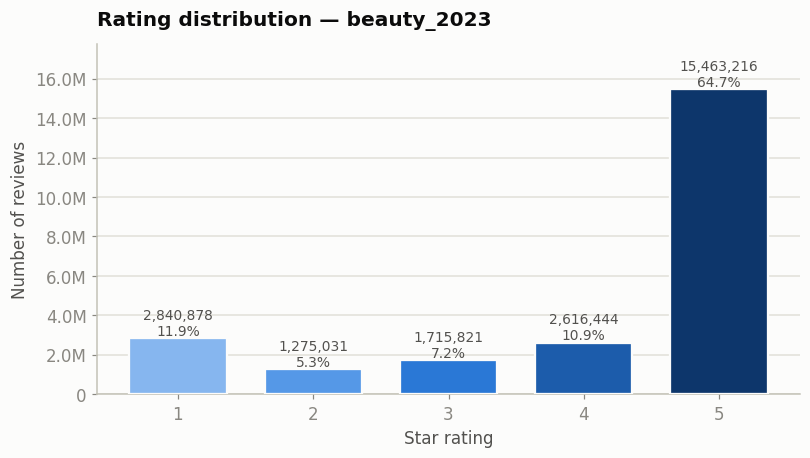

In [77]:
# --- Marginal: rating distribution ---------------------------------------------
rating_counts = reviews["rating"].value_counts().reindex(RATINGS, fill_value=0).to_numpy()
rating_share = rating_counts / rating_counts.sum()

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.bar(RATINGS, rating_counts, width=0.72, color=RATING_RAMP,
       edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.set_title(f"Rating distribution — {DATASET}", fontweight="bold", pad=12, loc="left")
ax.set_xlabel("Star rating")
ax.set_ylabel("Number of reviews")
ax.set_xticks(RATINGS)
ax.margins(y=0.15)
ax.yaxis.set_major_formatter(kfmt)
ax.grid(axis="x", visible=False)
for x, c, s in zip(RATINGS, rating_counts, rating_share):
    ax.text(x, c, f"{c:,}\n{s:.1%}", ha="center", va="bottom", fontsize=9, color=INK_2)
fig.tight_layout()
plt.show()


## 2. `verified_purchase` distribution

Share of reviews flagged as verified purchases. Any `null` flags are kept as an
explicit **Unknown** bucket rather than silently dropped. (Note: in the
`beauty_2014` log every review is verified, so this reduces to a single bar.)

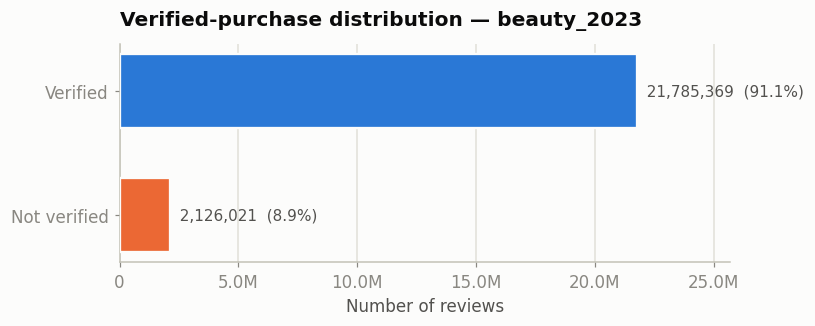

In [78]:
# --- Marginal: verified_purchase distribution ----------------------------------
present = [lab for lab in ("Verified", "Not verified", "Unknown")
           if (reviews["verified_label"] == lab).any()]
counts = np.array([(reviews["verified_label"] == lab).sum() for lab in present])

fig, ax = plt.subplots(figsize=(7.5, 2.4 + 0.35 * len(present)))
ypos = np.arange(len(present))[::-1]  # first label on top
ax.barh(ypos, counts, height=0.6, color=[COLOR_BY_LABEL[l] for l in present],
        edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(ypos)
ax.set_yticklabels(present)
ax.set_title(f"Verified-purchase distribution — {DATASET}", fontweight="bold", pad=12, loc="left")
ax.set_xlabel("Number of reviews")
ax.xaxis.set_major_formatter(kfmt)
ax.grid(axis="y", visible=False)
ax.margins(x=0.18)
for y, c in zip(ypos, counts):
    ax.text(c, y, f"  {c:,}  ({c / n:.1%})", va="center", ha="left", fontsize=10, color=INK_2)
fig.tight_layout()
plt.show()


## 3. Joint distribution — rating × verified

Two views of the same crosstab:

- **Left — joint counts:** absolute number of reviews for each (rating, verified) pair.
- **Right — verified share within each rating:** each bar normalised to 100%, so you
  can read *P(verified | rating)* directly and see whether higher-rated reviews are
  more likely to be verified.

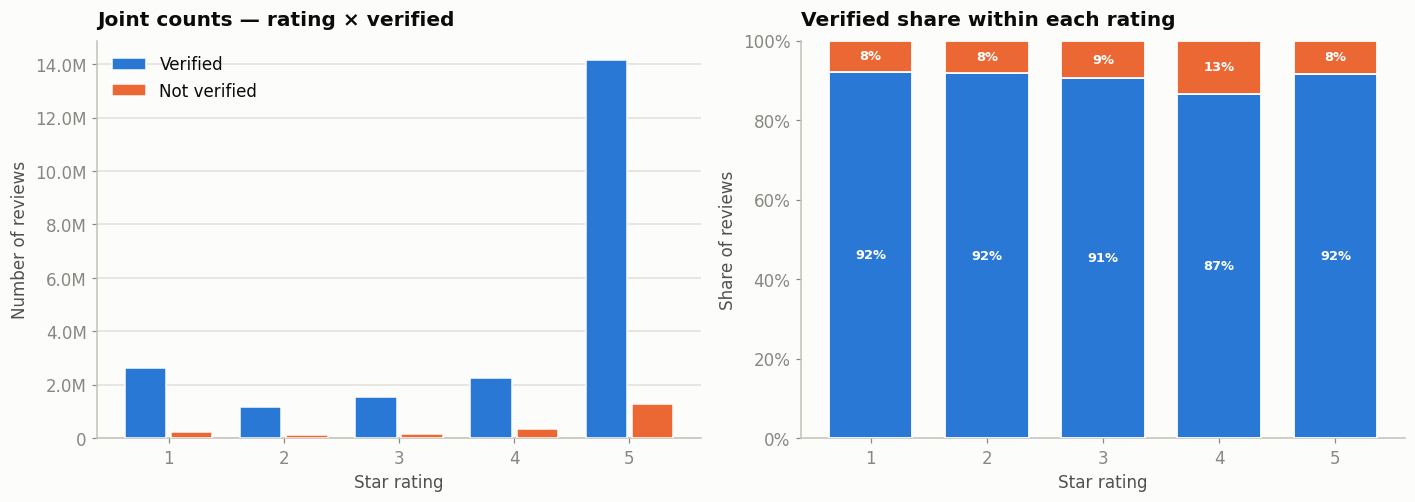

In [79]:
# --- Joint: rating x verified --------------------------------------------------
ct = pd.crosstab(reviews["rating"], reviews["verified_label"]).reindex(RATINGS, fill_value=0)
cats = [c for c in ("Verified", "Not verified", "Unknown") if c in ct.columns]
ct = ct[cats]
prop = ct.div(ct.sum(axis=1), axis=0)  # row-normalised: share within each rating

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.7))

# Left: grouped counts.
w = 0.8 / len(cats)
for i, cat in enumerate(cats):
    ax1.bar(RATINGS + (i - (len(cats) - 1) / 2) * w, ct[cat].to_numpy(), width=w * 0.9,
            color=COLOR_BY_LABEL[cat], edgecolor=SURFACE, linewidth=1.0, label=cat, zorder=3)
ax1.set_title("Joint counts — rating × verified", fontweight="bold", pad=10, loc="left")
ax1.set_xlabel("Star rating")
ax1.set_ylabel("Number of reviews")
ax1.set_xticks(RATINGS)
ax1.yaxis.set_major_formatter(kfmt)
ax1.grid(axis="x", visible=False)
ax1.legend(frameon=False, loc="upper left")

# Right: 100%-stacked verified share within each rating.
bottom = np.zeros(len(RATINGS))
for cat in cats:
    seg = prop[cat].to_numpy()
    ax2.bar(RATINGS, seg, bottom=bottom, width=0.72, color=COLOR_BY_LABEL[cat],
            edgecolor=SURFACE, linewidth=1.2, zorder=3)
    for x, val, b in zip(RATINGS, seg, bottom):
        if val > 0.05:
            ax2.text(x, b + val / 2, f"{val:.0%}", ha="center", va="center",
                     color=ink_on(COLOR_BY_LABEL[cat]), fontsize=8.5, fontweight="bold")
    bottom += seg
ax2.set_title("Verified share within each rating", fontweight="bold", pad=10, loc="left")
ax2.set_xlabel("Star rating")
ax2.set_ylabel("Share of reviews")
ax2.set_xticks(RATINGS)
ax2.set_ylim(0, 1)
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.grid(visible=False)

fig.tight_layout()
plt.show()


In [80]:
# --- Joint crosstab + summary statistics ---------------------------------------
print("Joint counts (rating × verified):")
print(ct.to_string())

print("\nVerified rate by rating  P(verified | rating):")
if "Verified" in ct.columns:
    vrate = (ct["Verified"] / ct.sum(axis=1))
    print(vrate.round(3).to_string())

print("\nMean rating by verified status  E[rating | verified]:")
print(reviews.groupby("verified_label", observed=True)["rating"]
      .agg(["mean", "count"]).round(3).to_string())


Joint counts (rating × verified):
verified_label  Verified  Not verified
rating                                
1                2618585        222293
2                1170590        104441
3                1554129        161692
4                2265763        350681
5               14176302       1286914

Verified rate by rating  P(verified | rating):
rating
1    0.922
2    0.918
3    0.906
4    0.866
5    0.917

Mean rating by verified status  E[rating | verified]:
                 mean     count
verified_label                 
Not verified    4.117   2126021
Verified        4.111  21785369


## 4. Missing / unset values (data quality)

Are there interactions where the **rating** or the **`verified_purchase`** flag is
not set at all — empty, `NaN`, `null`, or out of the valid 1–5 range?

We check on the loaded log and then sweep every dataset:

- `rating` missing (`NaN`) or outside the 1–5 range,
- `verified` missing (`null`),
- rows missing **either** field, and rows missing **both**.

> **Where the missingness actually lives.** The `dataframe_format/*.parquet` logs
> analysed above are *already cleaned*, so we expect ~0 missing here. The real gaps
> are **upstream** — the last cell inspects the converted implicit-feedback `.jsonl`
> logs that FlowRec's `AmazonLogRewardModel` actually consumes, where the flag is
> genuinely absent. That absence is exactly why `AmazonLogRewardConfig` treats the
> rating/verified fields as *optional* with an `unobserved_reward` fallback.

Missing-value report — beauty_2023  (n=23,911,390)
                          check  count  pct
           rating missing (NaN)      0  0.0
        rating out of 1-5 range      0  0.0
        verified missing (null)      0  0.0
 row missing rating OR verified      0  0.0
row missing rating AND verified      0  0.0


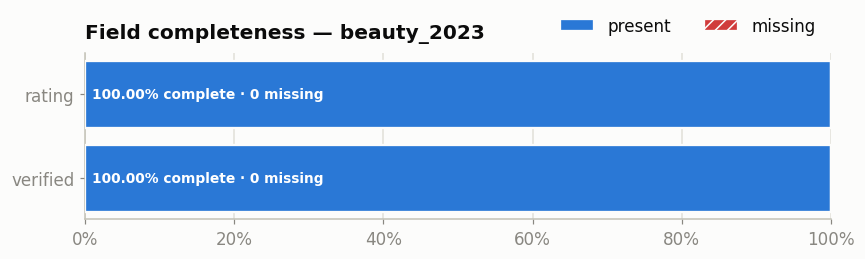

In [81]:
# --- Missing-value report for the loaded log -----------------------------------
def missingness_report(df, name):
    n = len(df)
    rating_na = df["rating"].isna()
    verified_na = df["verified"].isna()
    out_of_range = df["rating"].notna() & ((df["rating"] < 1) | (df["rating"] > 5))
    rows = [
        ("rating missing (NaN)",             int(rating_na.sum())),
        ("rating out of 1-5 range",          int(out_of_range.sum())),
        ("verified missing (null)",          int(verified_na.sum())),
        ("row missing rating OR verified",   int((rating_na | verified_na).sum())),
        ("row missing rating AND verified",  int((rating_na & verified_na).sum())),
    ]
    rep = pd.DataFrame(rows, columns=["check", "count"])
    rep["pct"] = (rep["count"] / n * 100).round(4)
    print(f"Missing-value report — {name}  (n={n:,})")
    print(rep.to_string(index=False))
    return rep

report = missingness_report(reviews, DATASET)

# --- Field-completeness bar (present vs missing) -------------------------------
C_PRESENT, C_MISSING = C_VERIFIED, "#d03b3b"   # blue = present, red = missing
FIELDS = ["rating", "verified"]
missing_frac = np.array([reviews[f].isna().mean() for f in FIELDS])
present_frac = 1 - missing_frac

fig, ax = plt.subplots(figsize=(8, 2.5))
ypos = np.arange(len(FIELDS))[::-1]
ax.barh(ypos, present_frac, color=C_PRESENT, edgecolor=SURFACE, linewidth=1.5,
        zorder=3, label="present")
ax.barh(ypos, missing_frac, left=present_frac, color=C_MISSING, edgecolor=SURFACE,
        linewidth=1.5, hatch="///", zorder=3, label="missing")
ax.set_yticks(ypos)
ax.set_yticklabels(FIELDS)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.set_title(f"Field completeness — {DATASET}", fontweight="bold", loc="left", pad=10)
for y, f, m in zip(ypos, FIELDS, missing_frac):
    ax.text(0.01, y, f"{1 - m:.2%} complete · {int(reviews[f].isna().sum()):,} missing",
            va="center", ha="left", color="white", fontsize=9, fontweight="bold")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.02), ncol=2)
fig.tight_layout()
plt.show()


In [82]:
# --- Sweep every parquet log for missing rating / verified ---------------------
sweep = []
for name in DATASETS:
    df = load_reviews(name)
    n = len(df)
    sweep.append({
        "dataset": name,
        "rows": n,
        "rating_missing": int(df["rating"].isna().sum()),
        "verified_missing": int(df["verified"].isna().sum()),
        "verified_true_%": round((df["verified"] == True).mean() * 100, 2),
        "verified_false_%": round((df["verified"] == False).mean() * 100, 2),
    })
sweep = pd.DataFrame(sweep)
print("Missingness across all parquet logs:")
print(sweep.to_string(index=False))


Missingness across all parquet logs:
         dataset     rows  rating_missing  verified_missing  verified_true_%  verified_false_%
instruments_2018  1512530               0                 0            89.00             11.00
     beauty_2023 23911390               0                 0            91.11              8.89
     beauty_2014  2023070               0                 0           100.00              0.00


In [83]:
# --- Upstream check: converted logs consumed by AmazonLogRewardModel -----------
# These *_converted_for_amazonreview.jsonl.gz logs are the implicit-feedback
# interactions the reward model reads. Unlike the cleaned parquet, the rating /
# verified_purchase fields here can be entirely unset (null) or synthetic.
import gzip
import json

RAW_DIR = DATA_DIR.parent  # data/raw
converted = sorted(RAW_DIR.glob("reviews_*converted_for_amazonreview.jsonl.gz"))

rows = []
for path in converted:
    n = rating_null = verified_null = 0
    rating_vals, verified_vals = set(), set()
    with gzip.open(path, "rt") as fh:
        for line in fh:
            d = json.loads(line)
            n += 1
            r = d.get("rating", d.get("overall"))
            v = d.get("verified_purchase", d.get("verified"))
            rating_null += r is None
            verified_null += v is None
            rating_vals.add(r)
            verified_vals.add(v)
    rows.append({
        "file": path.name.replace("_for_amazonreview.jsonl.gz", ""),
        "rows": n,
        "rating_null_%": round(rating_null / n * 100, 1),
        "verified_null_%": round(verified_null / n * 100, 1),
        "distinct_rating": sorted(x for x in rating_vals if x is not None),
        "distinct_verified": sorted(str(x) for x in verified_vals),
    })

upstream = pd.DataFrame(rows)
print("Rating / verified_purchase in the converted logs the reward model consumes:")
with pd.option_context("display.max_colwidth", 40):
    print(upstream.to_string(index=False))


Rating / verified_purchase in the converted logs the reward model consumes:
                                  file   rows  rating_null_%  verified_null_% distinct_rating distinct_verified
     reviews_Beauty_uploaded_converted 198502            0.0            100.0           [1.0]            [None]
reviews_Instruments_uploaded_converted 206153            0.0            100.0           [1.0]            [None]
               reviews_inter_converted 198502            0.0              0.0           [5.0]           [False]


### What the missingness check shows

- **The cleaned parquet logs have no unset values.** Across `instruments_2018`,
  `beauty_2023`, and `beauty_2014`, every row has a `rating` in 1–5 and a boolean
  `verified` flag — `0` missing on both. So for the modelling data there are **no
  interactions with an empty/NaN rating or verified flag**.
- **`verified` is structurally absent in the 2014 Amazon format.** The original
  `2014/reviews_Beauty.json` has no `verified` key at all — the field was only added
  in the 2018 dump. The parquet build backfills it as all-`True`, which is why
  `beauty_2014` shows `verified_false_% = 0`. Treat its "verified" column as *unknown*,
  not as a genuine 100%-verified signal.
- **The converted logs the reward model reads are where the flag is truly unset.**
  In the `*_uploaded_converted` implicit-feedback logs, `verified_purchase` is
  **100% null** and the rating is a synthetic constant — these are click/interaction
  logs, not rated reviews. `AmazonLogRewardModel` handles this gracefully: missing
  ratings/verified fall back to `unobserved_reward`, and the verified bonus is only
  applied when the flag is actually present.

## 5. Per-user reward distributions across reward modes

For a few random users (with their interaction prefix) we compute the reward of
**every item in the catalog** under each reward-generation mode and compare the
distributions:

| mode | description |
|---|---|
| `amazon_log / logged` | original scheme: normalized rating × verified bonus → `log1p`; unobserved items get `unobserved_reward` |
| `amazon_log / binary` | positive target → `positive_reward` (1.0), everything else → `unobserved_reward` |
| `amazon_log / item_centered` | multiplier `clip(exp(β·w·z))` around 1.0, where `z` is the item-mean-centered rating residual and `w` down-weights unverified evidence |
| `sasrec / <transform>` | tuned-SASRec next-item scores mapped to a positive reward by each `SASRecRewardConfig.transform`: `softplus`, `sigmoid`, `identity`, `exp`, `minmax_batch`, `rank_percentile` |
| `sasrec × ic / <transform>` | `MultiplicativeRewardModel`: the collaborative reward **multiplied** by the `item_centered` modulator, per transform |
| `sasrec + ic / <transform>` | `MixedRewardModel` (`scripts/run_tiger.py`, `reward.name="mix"`): batch_max-normalized weighted **sum** of the collaborative reward and the `item_centered` modulator, per transform |

**Setup.** This section always uses **instruments** (independent of the `DATASET`
variable above), because that is what the tuned SASRec checkpoint
`checkpoints/exp2-tuned-params/sasrec/instruments` was trained on. Data
preprocessing replicates `scripts/tiger_for_small_hard.py` (leave-one-out, 5-core,
`max_history_len=20`), plus the semantic-ID catalog filter from
`scripts/rewards_ablation.py` — filtering to the semantic-ID item set *before*
k-core/factorization reproduces the exact item IDs the checkpoint was trained on.
Users are drawn from the test split, so the prefix is the user's full history
minus the held-out target.

In [84]:
# --- FlowRec setup: datamodule (tiger_for_small_hard preprocessing) + SASRec ---
import sys

import torch

PROJECT_ROOT = next(
    p for p in (Path.cwd(), Path.cwd().parent)
    if (p / "flowrec").exists() and (p / "data" / "raw").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from flowrec.data.datamodule import AmazonReviewDataConfig, AmazonReviewDataModule
from flowrec.models.sasrec import SASRec, SASRecConfig

dm = AmazonReviewDataModule(
    AmazonReviewDataConfig(
        reviews_path=PROJECT_ROOT / "data/raw/dataframe_format/reviews_instruments_2018.parquet",
        metadata_path=PROJECT_ROOT / "data/raw/dataframe_format/meta_instruments_2018.parquet",
        # Filtering to the semantic-ID catalog before k-core / factorization
        # reproduces the item IDs the tuned SASRec checkpoint was trained on
        # (same recipe as scripts/rewards_ablation.py).
        semantic_id_path=PROJECT_ROOT / "datasets/semantic_ids/exp1-standard params/instruments/semantic_ids.json",
        drop_items_missing_semantic_id=True,
        item_key="asin",
        split_strategy="leave_one_out",
        train_all_prefixes=True,
        min_user_interactions=5,
        min_item_interactions=5,
        max_history_len=20,
        deduplicate_consecutive=False,
        filter_cold_items_after_split=False,
        batch_size=128,
        eval_batch_size=64,
        num_workers=0,
        pin_memory=False,
        persistent_workers=False,
        offset_semantic_ids_by_one=True,
        seed=43,
    )
)
dm.setup()
print(f"datamodule: users={dm.num_users:,}  items={dm.num_items:,}  "
      f"vocab={dm.item_vocab_size}  test examples={len(dm.test_dataset):,}")

SASREC_CKPT = PROJECT_ROOT / "checkpoints/exp2-tuned-params/sasrec/instruments/tuned_sasrec_instruments.pt"
payload = torch.load(SASREC_CKPT, map_location="cpu", weights_only=False)
assert payload["model_config"]["item_vocab_size"] == dm.item_vocab_size, (
    "SASRec checkpoint vocab does not match the datamodule — "
    "the preprocessing above must reproduce the training-time item catalog."
)
sasrec = SASRec(SASRecConfig(**payload["model_config"]))
sasrec.load_state_dict(payload["model_state_dict"])
sasrec.eval()
print(f"SASRec loaded: {payload['model_config']}")

datamodule: users=27,390  items=10,439  vocab=10440  test examples=27,390
SASRec loaded: {'item_vocab_size': 10440, 'max_history_len': 20, 'd_model': 256, 'nhead': 8, 'num_layers': 4, 'dropout': 0.21494926371335477, 'pos_drop': 0.18784622651037045}


In [85]:
# --- Sample random users with their prefix; full-catalog candidate set ---------
from flowrec.trajectories.semantic import SemanticTrajectoryBatch

N_USERS = 4
rng = np.random.default_rng(7)
test_idxs = rng.choice(len(dm.test_dataset), size=N_USERS, replace=False)
examples = [dm.test_dataset[int(i)] for i in test_idxs]
batch = dm._make_collator()(examples)

for col in range(N_USERS):
    h = int(batch["history_mask"][col].sum())
    prefix = batch["history_item_ids"][col][batch["history_mask"][col]].tolist()
    print(f"user {int(batch['user_ids'][col]):>6}  prefix({h}): {prefix}  ->  "
          f"target {int(batch['target_item_ids'][col])} "
          f"({batch['target_ratings'][col]:.0f}★, "
          f"{'verified' if bool(batch['target_verified_purchase'][col]) else 'unverified'})")

# Every catalog item is a candidate trajectory; the held-out target is positive.
catalog = torch.arange(1, dm.item_vocab_size, dtype=torch.long)  # 0 is padding
N_CATALOG = catalog.numel()
candidate_item_ids = catalog.unsqueeze(0).expand(N_USERS, N_CATALOG)
is_positive = candidate_item_ids.eq(batch["target_item_ids"].unsqueeze(1))
traj = SemanticTrajectoryBatch(
    candidate_token_ids=torch.zeros((N_USERS, N_CATALOG, 1), dtype=torch.long),
    candidate_token_mask=torch.ones((N_USERS, N_CATALOG, 1), dtype=torch.bool),
    is_positive=is_positive,
    extra={"candidate_item_ids": candidate_item_ids},
)
print(f"\ncandidates: {N_USERS} users x {N_CATALOG:,} catalog items")


user  25878  prefix(5): [3854, 3855, 1469, 14, 3041]  ->  target 3634 (5★, verified)
user  17120  prefix(6): [9175, 1321, 110, 1185, 2055, 533]  ->  target 2216 (5★, verified)
user  24574  prefix(4): [2288, 2653, 3710, 2652]  ->  target 771 (5★, unverified)
user  18739  prefix(6): [151, 1808, 22, 1971, 469, 1859]  ->  target 3164 (1★, verified)

candidates: 4 users x 10,439 catalog items


In [86]:
# --- Build all reward modes and score the full catalog per user ----------------
from flowrec.rewards.amazon_log import (
    AmazonLogRewardConfig,
    AmazonLogRewardModel,
    compute_item_mean_ratings,
)
from flowrec.rewards.mix import MultiplicativeRewardModel
from flowrec.rewards.sasrec import SASRecRewardConfig, SASRecRewardModel

# Additive mixing lives in the training script: MixedRewardModel is the exact
# model run_tiger builds for reward.name == "mix" (batch_max-normalized sum).
if str(PROJECT_ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from run_tiger import MixedRewardModel

item_means, global_mean = compute_item_mean_ratings(
    torch.tensor(dm.interactions["item_id"].to_numpy()),
    torch.tensor(dm.interactions["rating"].to_numpy(dtype="float32")),
    num_items=dm.item_vocab_size,
    shrinkage=10.0,
)
print(f"item mean ratings: global={global_mean:.3f}")

item_centered = AmazonLogRewardModel(
    AmazonLogRewardConfig(reward_mode="item_centered"),
    item_mean_rating=item_means,
    global_mean_rating=global_mean,
)

TRANSFORMS = ["softplus", "sigmoid", "identity", "exp", "minmax_batch", "rank_percentile"]
sasrec_by_transform = {
    t: SASRecRewardModel(sasrec, SASRecRewardConfig(transform=t)) for t in TRANSFORMS
}

REWARD_MODES = {
    "amazon_log / logged": AmazonLogRewardModel(AmazonLogRewardConfig()),
    "amazon_log / binary": AmazonLogRewardModel(AmazonLogRewardConfig(reward_mode="binary")),
    "amazon_log / item_centered": item_centered,
}
# SASRec under every transform, then its two derivatives: multiplication
# (MultiplicativeRewardModel) and summation (MixedRewardModel).
REWARD_MODES.update({f"sasrec / {t}": sasrec_by_transform[t] for t in TRANSFORMS})
REWARD_MODES.update({
    f"sasrec × ic / {t}": MultiplicativeRewardModel([sasrec_by_transform[t], item_centered])
    for t in TRANSFORMS
})
REWARD_MODES.update({
    f"sasrec + ic / {t}": MixedRewardModel([sasrec_by_transform[t], item_centered])
    for t in TRANSFORMS
})

rewards = {}
with torch.no_grad():
    for mode, model in REWARD_MODES.items():
        rewards[mode] = model(batch, traj).float()

# Where does the positive target sit inside each full-catalog distribution?
summary = pd.DataFrame(
    {
        mode: {
            f"user {int(batch['user_ids'][col])}": float(
                (r[col] < r[col][is_positive[col]]).float().mean() * 100
            )
            for col in range(N_USERS)
        }
        for mode, r in rewards.items()
    }
).T.round(1)
print("\nTarget percentile within the full-catalog reward distribution (higher = better separated):")
print(summary.to_string())

item mean ratings: global=4.471

Target percentile within the full-catalog reward distribution (higher = better separated):
                               user 25878  user 17120  user 24574  user 18739
amazon_log / logged                 100.0        99.9       100.0         0.0
amazon_log / binary                 100.0       100.0       100.0       100.0
amazon_log / item_centered          100.0       100.0       100.0         0.0
sasrec / softplus                    78.5        82.5         5.4        99.9
sasrec / sigmoid                     78.5        82.5         5.4        99.9
sasrec / identity                    78.5        82.5         0.0        99.9
sasrec / exp                         78.5        82.5         5.4        99.9
sasrec / minmax_batch                78.5        82.5         5.4        99.9
sasrec / rank_percentile             78.5        82.5         5.4        99.9
sasrec × ic / softplus               92.0        94.7         8.7        84.3
sasrec × ic / sigm

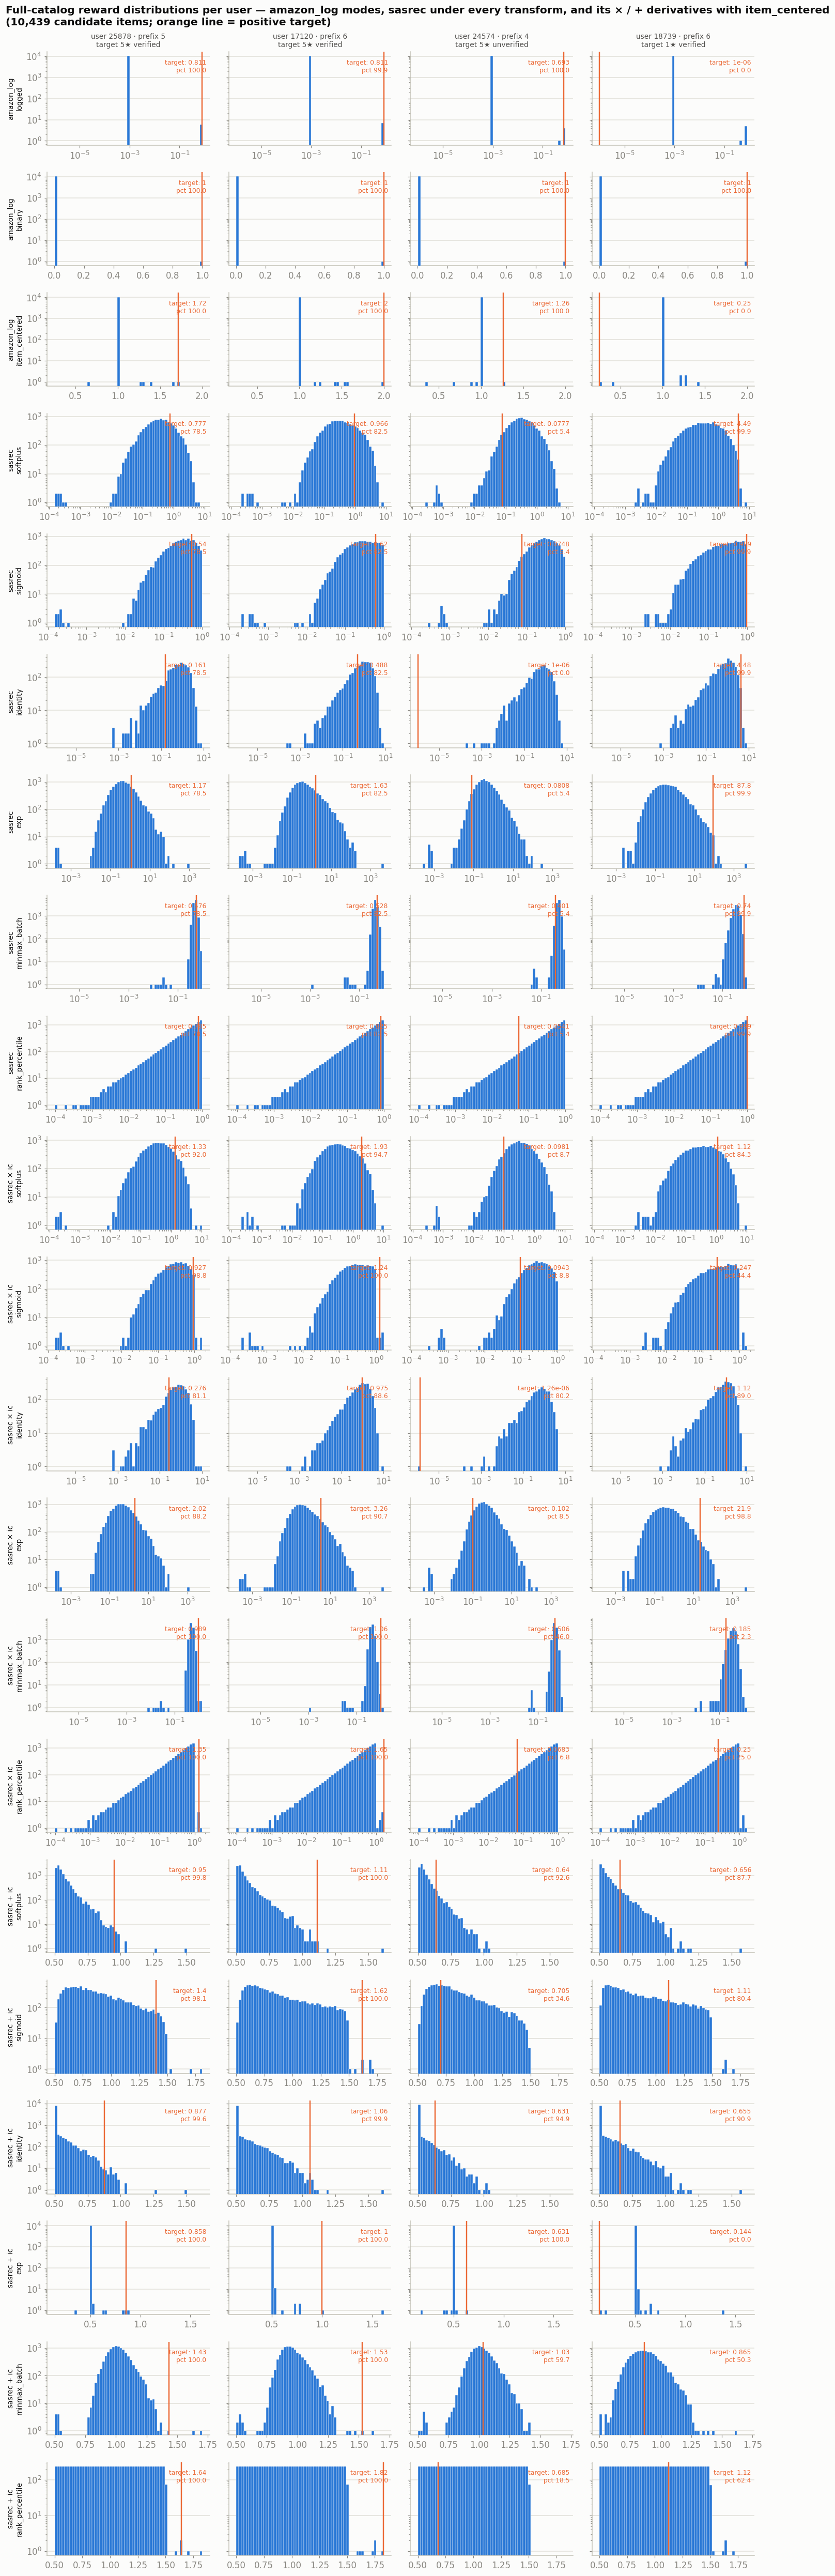

In [87]:
# --- Plot: full-catalog reward distribution per user, one row per mode ---------
mode_names = list(REWARD_MODES)
fig, axes = plt.subplots(
    len(mode_names), N_USERS,
    figsize=(3.4 * N_USERS, 2.2 * len(mode_names)),
    sharex="row", sharey="row",
)

for row, mode in enumerate(mode_names):
    r = rewards[mode].numpy()
    # Rows whose reward spans >3 decades (exp, identity, the × ic products)
    # are binned and drawn on a log x-axis so the shape stays readable.
    lo, hi = max(r.min(), 1e-6), r.max()
    log_x = hi / lo > 1e3
    bins = (np.logspace(np.log10(lo), np.log10(hi * 1.001), 60)
            if log_x else np.linspace(lo, hi * 1.001, 60))
    for col in range(N_USERS):
        ax = axes[row, col]
        ax.hist(r[col], bins=bins, color=C_VERIFIED, edgecolor=SURFACE,
                linewidth=0.3, zorder=3)
        ax.set_yscale("log")
        if log_x:
            ax.set_xscale("log")
        tgt = float(r[col][is_positive[col].numpy()][0])
        pct = float((r[col] < tgt).mean() * 100)
        ax.axvline(tgt, color=C_UNVERIFIED, linewidth=1.6, zorder=4)
        ax.text(0.98, 0.92, f"target: {tgt:.3g}\npct {pct:.1f}",
                transform=ax.transAxes, ha="right", va="top",
                fontsize=8, color=C_UNVERIFIED)
        ax.grid(axis="x", visible=False)
        if row == 0:
            h = int(batch["history_mask"][col].sum())
            rt = batch["target_ratings"][col].item()
            ver = "verified" if bool(batch["target_verified_purchase"][col]) else "unverified"
            ax.set_title(
                f"user {int(batch['user_ids'][col])} · prefix {h}\ntarget {rt:.0f}★ {ver}",
                fontsize=9, color=INK_2,
            )
        if col == 0:
            ax.set_ylabel(mode.replace(" / ", "\n"), fontsize=9, color=INK)

fig.suptitle(
    "Full-catalog reward distributions per user — amazon_log modes, sasrec under "
    "every transform, and its × / + derivatives with item_centered\n"
    f"({N_CATALOG:,} candidate items; orange line = positive target)",
    fontweight="bold", x=0.01, ha="left",
)
fig.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

### Reading the reward distributions

- **`logged` and `binary` are near-degenerate:** virtually the whole catalog sits
  at `unobserved_reward` (the tall spike at ~0), with only the target and a
  handful of history items separated. Within the positives these modes barely
  discriminate — and in `logged` mode a 1★ target collapses *below* the unobserved
  floor (percentile 0), i.e. the model is told the user's actual purchase is worse
  than a random unseen item.
- **`item_centered` is a multiplier, not a stand-alone reward:** the mass at 1.0
  is every unobserved item (neutral, "no evidence"), and the logged interactions
  spread across [0.25, 2] according to how far the rating sits from the item's
  typical rating (trust-weighted by the verified flag).
- **`sasrec / *` is dense:** a smooth, discriminating distribution over the whole
  catalog — but it knows nothing about the logged rating: it can rank a 1★
  purchase very highly (user 18739: pct 99.9). All transforms are monotone in
  the score, so the target percentile is **identical in every `sasrec / *` row**
  (78.5 / 82.5 / 5.4 / 99.9) — only the *shape* (the reward ratios) changes.
  The one exception is `identity`, which clamps negative scores to
  `reward_epsilon` and collapses roughly half the catalog (incl. user 24574's
  target) into a single spike.
- **`sasrec × ic` re-ranks with logged evidence while keeping the SASRec shape:**
  unobserved items keep their collaborative reward (multiplier 1.0), only logged
  items move — the 5★ targets push right (user 25878: 78.5 → 92.0 under
  softplus), the 1★ target pulls back (user 18739: 99.9 → 84.3 softplus,
  44.4 sigmoid). The unverified 5★ target (user 24574) barely moves
  (5.4 → 8.7) because the trust weight damps its multiplier.
- **`sasrec + ic` lets the modulator dominate:** `MixedRewardModel` divides each
  component by its batch max before summing, and the SASRec max is an outlier —
  so the normalized collaborative term is ≈ 0 for the bulk of the catalog and
  `item_centered` decides the ranking (user 24574's unverified 5★ jumps
  5.4 → 92.6). The distributions are visibly compressed (note the narrow x-range)
  and in the `exp` row the sum degenerates to `item_centered` alone: the 1★
  target falls back to percentile 0 — the cliff the multiplicative composition
  avoids.

### 5.1 Numeric summary — SASRec transforms and derivatives

The full-catalog plot above shows the shapes; the table below condenses every
`sasrec` variant (alone, `× ic`, `+ ic` — each under every
`SASRecRewardConfig.transform`) into three numbers:

- **target percentile** — where the positive target ranks in the full catalog.
  Pure transforms are monotone in the score, so it is identical across the
  `sasrec / *` rows; the `× ic` / `+ ic` derivatives *do* change it, because the
  logged-evidence modulator re-ranks observed items;
- **target/median contrast** — how strongly the reward prefers the target over a
  typical catalog item;
- **`log R` std** — the effective sharpness (temperature) of the reward
  landscape, which is what the trajectory-balance loss (`log R`) actually
  optimizes.

> **TB-safety note** (cf. `TB_SAFE_SASREC_TRANSFORMS` in
> `scripts/rewards_ablation.py`): `softplus`, `sigmoid`, `identity`, `exp` are
> pointwise — fixed terminal rewards — and so are their `× ic` products
> (`item_centered` is pointwise too). `minmax_batch` and `rank_percentile` are
> normalized *per candidate set*, and so is **every** `+ ic` row:
> `MixedRewardModel` divides each component by its batch max
> (`uses_candidate_set_normalization=True` in `scripts/run_tiger.py`). Those are
> inconsistent with a precomputed full-catalog logZ and shown for shape
> comparison only.

In [88]:
# --- Numeric summary per sasrec variant (reuses the full-catalog rewards) ------
rows = []
for mode, r in rewards.items():
    if not mode.startswith("sasrec"):
        continue
    tgt = r[is_positive]
    pct = (r < tgt.unsqueeze(1)).float().mean(1) * 100
    contrast = tgt / r.median(dim=1).values
    log_r_std = torch.log(r.clamp_min(1e-6)).std()
    rows.append({
        "variant": mode,
        **{f"pct u{int(batch['user_ids'][i])}": round(float(p), 1) for i, p in enumerate(pct)},
        **{f"tgt/med u{int(batch['user_ids'][i])}": round(float(c), 2) for i, c in enumerate(contrast)},
        "logR std": round(float(log_r_std), 2),
    })
transform_summary = pd.DataFrame(rows)
print("Target percentile, target/median contrast, and logR std per sasrec variant:")
print(transform_summary.to_string(index=False))

Target percentile, target/median contrast, and logR std per sasrec variant:
                      variant  pct u25878  pct u17120  pct u24574  pct u18739  tgt/med u25878  tgt/med u17120  tgt/med u24574  tgt/med u18739  logR std
            sasrec / softplus        78.5        82.5         5.4        99.9            2.13            2.91            0.24           13.20      1.03
             sasrec / sigmoid        78.5        82.5         5.4        99.9            1.77            2.19            0.27            3.43      0.83
            sasrec / identity        78.5        82.5         0.0        99.9       160896.84       487500.38            1.00      4475030.50      5.77
                 sasrec / exp        78.5        82.5         5.4        99.9            2.67            4.13            0.21          216.91      1.33
        sasrec / minmax_batch        78.5        82.5         5.4        99.9            1.12            1.19            0.78            2.03      0.29
     sasrec 

### Reading the transform / derivative comparison

**Pure transforms (`sasrec / *`)** — percentiles identical in every row
(78.5 / 82.5 / 5.4 / 99.9); the transform only sets the contrast:

- **`sigmoid` compresses** (`log R` std ≈ 0.8): scores saturate toward 1, so the
  reward barely prefers the target over the median item (contrast ≈ 2–3×). Mild,
  stable, but low signal. **`minmax_batch` compresses even harder** (std ≈ 0.3).
- **`softplus` (default) is the balanced middle** (std ≈ 1.0): roughly
  log-normal, contrast 2–13×, no cliffs.
- **`exp` is the sharpest usable transform** (std ≈ 1.3, contrast up to ~200×):
  since TB works on `log R`, `exp` means the reward *is* the raw score up to
  temperature — sensible, but the right tail dominates logZ, so it effectively
  trains the policy to concentrate on top-scored items.
- **`rank_percentile`** is uniform by construction — pure ranking information
  with a bounded scale, but per-candidate-set (see TB-safety note above).
- **`identity`** clamps negative scores to `reward_epsilon`: half the catalog
  (and user 24574's target) collapses into the ε-spike, and its huge contrast
  numbers (~10⁵–10⁶) are meaningless ratios against that floor.

**Multiplication (`sasrec × ic`)** — keeps the base transform's `log R` std
*exactly* (the modulator is 1.0 almost everywhere) and re-ranks only logged
items: 5★ targets rise (u25878: 78.5 → 92.0 softplus, 98.8 sigmoid), the 1★
target drops (u18739: 99.9 → 84.3 softplus, 44.4 sigmoid), and the unverified
5★ moves barely at all (u24574: 5.4 → 8.7) because trust-weighting damps its
multiplier. How far the same multiplier moves an item depends on the local
density of the base distribution — flat `sigmoid` / `rank_percentile` translate
it into much larger rank shifts than heavy-tailed `exp` (u18739 stays at 98.8).
The u24574 jump under `identity` (0 → 80.2) is an artifact: any multiplier > 1
escapes the ε-spike. This is the composition `MultiplicativeRewardModel` was
designed for.

**Summation (`sasrec + ic`)** — batch_max normalization makes the sum
modulator-dominated: SASRec's max is an outlier, so its normalized term is ≈ 0
for the bulk of the catalog and `item_centered` decides the ranking (u24574's
unverified 5★ leaps 5.4 → 92.6, ignoring the trust damping that the product
respects). `log R` std collapses to 0.01–0.31 (vs ≈ 1 for the base transforms) —
a very weak TB gradient — and with `exp` the collaborative term vanishes
entirely: the row degenerates to `item_centered` alone and the 1★ target lands
at percentile 0, the exact `logged`-mode cliff the multiplicative composition
avoids.

### 5.2 Semantic-ID similarity to the positive item

Before analyzing similarity-based rewards, we look at the raw similarity signal
itself. `SimilarityRewardModel` (`flowrec/rewards/similarity.py`) defines the
similarity of a candidate to the positive target as the **number of semantic-ID
token positions they share, scaled to [0, 1]** — positionwise equality, not
prefix overlap. The semantic IDs are the RQ codes from
`datasets/semantic_ids/exp1-standard params/instruments/semantic_ids.json` —
the same file the datamodule loads in the setup cell. Each item has **4 RQ
levels from 256-entry codebooks plus a 5th collision-disambiguation token**
(appended by the tokenizer's `random_append` policy to separate the 118 items
whose 4-level codes collided); tokens are offset by one so 0 stays reserved
for padding.

For each of the four users we compute the similarity of **every catalog item**
to the held-out positive and look at its distribution. With `sid_len = 5` the
similarity can only take six values: 0, 0.2, …, 1. The cell below also rebuilds
the full-catalog candidate batch with the *real* semantic tokens (`traj_sem`) —
unlike `traj` above, whose dummy tokens only support item-level reward models —
so token-level reward models can score it directly.

In [89]:
# --- Semantic-ID similarity of every catalog item to the positive target -------
from flowrec.rewards.similarity import SimilarityRewardConfig, SimilarityRewardModel

SID_LEN = dm.sid_len
print(f"semantic IDs: {dm.semantic_id_path}")
print(f"sid_len={SID_LEN}, items with semantic IDs: {len(dm.semantic_ids):,}")

# Semantic-ID token table for the whole catalog (row = internal item id).
# dm.semantic_ids is keyed by raw ASIN with tokens already offset by one
# (0 is reserved for padding), and covers every catalog item because the
# datamodule dropped items without a semantic ID.
token_ids_by_item = torch.zeros((dm.item_vocab_size, SID_LEN), dtype=torch.long)
token_mask_by_item = torch.zeros((dm.item_vocab_size, SID_LEN), dtype=torch.bool)
for item_id in range(1, dm.item_vocab_size):
    tokens = dm.semantic_ids[dm.id_to_raw_item(item_id)]
    n = min(len(tokens), SID_LEN)
    token_ids_by_item[item_id, :n] = torch.as_tensor(tokens[:n], dtype=torch.long)
    token_mask_by_item[item_id, :n] = True
assert bool(token_mask_by_item[1:].all()), "every catalog item should have a full semantic ID"

# Same full-catalog candidate set as above, but with REAL semantic tokens, so
# token-level reward models (SimilarityRewardModel) can score it too.
traj_sem = SemanticTrajectoryBatch(
    candidate_token_ids=token_ids_by_item[catalog].unsqueeze(0).expand(N_USERS, N_CATALOG, SID_LEN),
    candidate_token_mask=token_mask_by_item[catalog].unsqueeze(0).expand(N_USERS, N_CATALOG, SID_LEN),
    is_positive=is_positive,
    extra={"candidate_item_ids": candidate_item_ids},
)

# sanity: the collator's target tokens must equal the catalog rows of the targets
assert torch.equal(batch["target_token_ids"], token_ids_by_item[batch["target_item_ids"]])

similarity_model = SimilarityRewardModel(SimilarityRewardConfig())
with torch.no_grad():
    similarity = similarity_model(batch, traj_sem).float()  # [B, N] = matched positions / SID_LEN
matched = (similarity * SID_LEN).round().long()             # 0..SID_LEN matching token positions

# Distribution of similarity levels per user.
levels = torch.arange(SID_LEN + 1)
dist = pd.DataFrame(
    {
        f"user {int(batch['user_ids'][col])}": [
            int((matched[col] == k).sum()) for k in levels
        ]
        for col in range(N_USERS)
    },
    index=[f"{int(k)}/{SID_LEN} (sim {k / SID_LEN:.2f})" for k in levels],
)
dist.loc["mean similarity"] = [round(float(similarity[c].mean()), 4) for c in range(N_USERS)]
print("\nItems by number of semantic-ID positions shared with the positive target:")
print(dist.to_string())

# How discriminative is each codebook level? Items sharing the target's token
# at position l (independently of the other positions).
n_codes = int(token_ids_by_item[1:].max())
per_pos = pd.DataFrame(
    {
        f"user {int(batch['user_ids'][col])}": [
            int((token_ids_by_item[catalog][:, l] == batch["target_token_ids"][col, l]).sum())
            for l in range(SID_LEN)
        ]
        for col in range(N_USERS)
    },
    index=[f"position {l + 1}" for l in range(SID_LEN)],
)
print(f"\nItems sharing the target's token at each position (of {N_CATALOG:,}; chance ≈ {N_CATALOG / n_codes:.0f}):")
print(per_pos.to_string())

semantic IDs: /Users/anaxagor/Documents/projects/flowrec/datasets/semantic_ids/exp1-standard params/instruments/semantic_ids.json
sid_len=5, items with semantic IDs: 10,439

Items by number of semantic-ID positions shared with the positive target:
                 user 25878  user 17120  user 24574  user 18739
0/5 (sim 0.00)   10222.0000   10135.000  10129.0000  10353.0000
1/5 (sim 0.20)     216.0000     298.000    304.0000     85.0000
2/5 (sim 0.40)       0.0000       5.000      5.0000      0.0000
3/5 (sim 0.60)       0.0000       0.000      0.0000      0.0000
4/5 (sim 0.80)       0.0000       0.000      0.0000      0.0000
5/5 (sim 1.00)       1.0000       1.000      1.0000      1.0000
mean similarity      0.0042       0.006      0.0061      0.0017

Items sharing the target's token at each position (of 10,439; chance ≈ 41):
            user 25878  user 17120  user 24574  user 18739
position 1          40          83          96          10
position 2          72          76          3

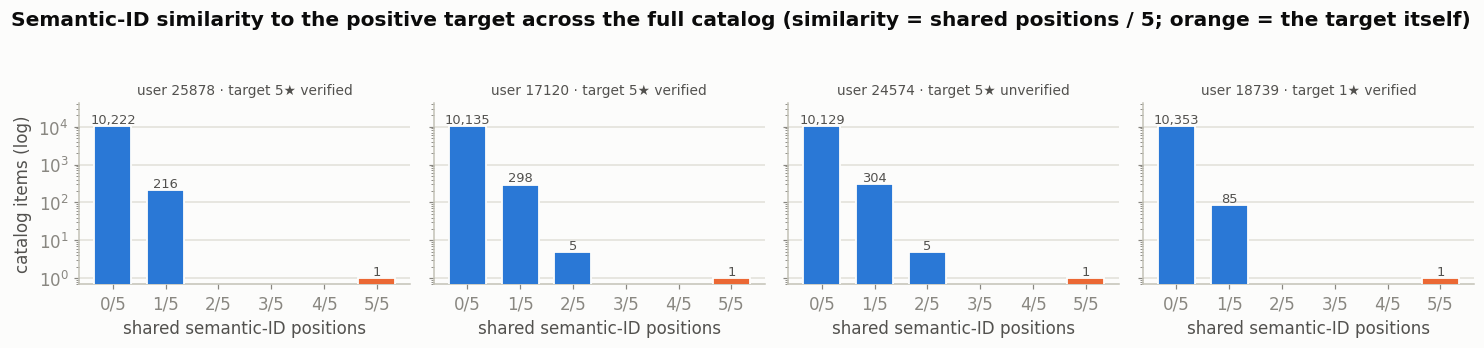

In [90]:
# --- Plot: distribution of semantic-ID similarity to the positive target -------
fig, axes = plt.subplots(1, N_USERS, figsize=(3.4 * N_USERS, 3.2), sharey=True)

level_axis = np.arange(SID_LEN + 1)
for col in range(N_USERS):
    ax = axes[col]
    counts = np.array([int((matched[col] == k).sum()) for k in level_axis])
    colors = [C_VERIFIED] * SID_LEN + [C_UNVERIFIED]  # 4/4 is the target itself
    ax.bar(level_axis, counts, width=0.7, color=colors, edgecolor=SURFACE,
           linewidth=1.2, zorder=3)
    ax.set_yscale("log")
    ax.set_ylim(0.7, counts.max() * 4)
    for x, c in zip(level_axis, counts):
        if c > 0:
            ax.text(x, c, f"{c:,}", ha="center", va="bottom",
                    fontsize=8.5, color=INK_2)
    ax.set_xticks(level_axis)
    ax.set_xticklabels([f"{k}/{SID_LEN}" for k in level_axis])
    ax.set_xlabel("shared semantic-ID positions")
    ax.grid(axis="x", visible=False)
    rt = batch["target_ratings"][col].item()
    ver = "verified" if bool(batch["target_verified_purchase"][col]) else "unverified"
    ax.set_title(f"user {int(batch['user_ids'][col])} · target {rt:.0f}★ {ver}",
                 fontsize=9, color=INK_2)
axes[0].set_ylabel("catalog items (log)")

fig.suptitle(
    "Semantic-ID similarity to the positive target across the full catalog "
    f"(similarity = shared positions / {SID_LEN}; orange = the target itself)",
    fontweight="bold", x=0.01, ha="left",
)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

### Reading the similarity distribution

- **The landscape is a delta at the target plus thin noise.** 97–99% of the
  catalog shares **0 of 5** positions with the target (10,135–10,353 of 10,439
  items), 0.8–2.9% shares exactly one (85–304 items), at most 5 items share
  two, **no item shares three or more**, and the only 5/5 item is the target
  itself. Mean similarity is 0.002–0.006.
- **A single shared position is near-chance information.** Each codebook has
  256 entries, so a random item matches a given position with p ≈ 1/256 —
  about 41 of 10,439 items. The observed per-position counts (10–96) scatter
  around that level, i.e. the RQ levels are individually weak discriminators
  and roughly independent; sharing one token says little about sharing another.
  (User 18739's counts of 10–20 across positions mean its target sits in rare
  clusters at every level.)
- **The measure is positionwise, not hierarchical.** `SimilarityRewardModel`
  counts a match at any position equally, so an item agreeing only in the last
  token (the random collision suffix!) scores the same 0.2 as one agreeing in
  the first (coarse cluster) — the RQ hierarchy is ignored.
- **Consequence for a similarity-based reward:** with only 6 possible values
  and ~98% of the mass at the ε-floor, the terminal reward is close to
  `amazon_log / binary` — a spike on the target with a small graded shoulder of
  a few dozen "cousins" — rather than a dense, smooth signal like `sasrec`.

### 5.3 Gower over semantic-ID tokens — ordinal within-codebook distance

The exact-match token similarity above is near-binary, and direct token matches
are rare. Here we reformulate the Gower logic **using semantic IDs only** (no
ratings, popularity, or categories): each codebook level becomes one Gower
feature, and levels get **different weights** following the RQ residual
hierarchy (level 1 encodes the coarsest structure, deeper levels only refine
it).

**Weighted Gower.** For items $a, b$ with codes $c_{a\ell}$ at levels
$\ell = 1 \dots L$ (every level is observed for every item, so Gower's
missing-feature indicator $\delta_\ell$ is always 1 and drops out):

$$
S(a,b) = \frac{\sum_{\ell=1}^{L} w_\ell\, s_\ell(a,b)}{\sum_{\ell=1}^{L} w_\ell},
\qquad
D_{\text{Gower}}(a,b) = 1 - S(a,b),
\qquad
w_\ell = 2^{-(\ell-1)} = 1, \tfrac{1}{2}, \tfrac{1}{4}, \dots
$$

The terminal reward against the positive target $t$ is
$R(a) = \max\bigl(S(a,t),\, \varepsilon\bigr)$ with $\varepsilon = 10^{-6}$.
The per-level similarity $s_\ell \in [0,1]$ is what distinguishes the variants:

- **exact match** (categorical Gower):
  $s_\ell = \mathbb{1}\left[c_{a\ell} = c_{b\ell}\right]$
- **index distance** (numeric Gower on token indices; assumes nearby indices —
  50 vs 51 — encode similar things):
  $s_\ell = 1 - \dfrac{\lvert c_{a\ell} - c_{b\ell} \rvert}{R_\ell}$,
  with $R_\ell \approx 255$ the index range at level $\ell$
- **codebook distance** (numeric Gower in the quantizer's latent space):
  $s_\ell = 1 - \dfrac{\lVert \mathbf{e}_\ell(c_{a\ell}) - \mathbf{e}_\ell(c_{b\ell}) \rVert_2}{\max_{u,v} \lVert \mathbf{e}_\ell(u) - \mathbf{e}_\ell(v) \rVert_2}$,
  where $\mathbf{e}_\ell(\cdot)$ is the RQ-VAE codebook vector at level $\ell$
  (loaded from `model.pt` next to the semantic IDs in
  `datasets/semantic_ids/exp1-standard params/instruments/`); the max-distance
  denominator is Gower's feature range carried into a metric space

| variant | per-level similarity $s_\ell$ | level weights $w_\ell$ |
|---|---|---|
| `exact match · equal w` | exact match | equal — reduces *exactly* to the 5.2 similarity (asserted) |
| `\|Δtoken\| · equal w` | index distance | equal |
| `\|Δtoken\| · level-decay w` | index distance | $2^{-(\ell-1)}$: 1, ½, ¼, … |
| `codebook dist · equal w` | codebook distance | equal |
| `codebook dist · level-decay w` | codebook distance | $2^{-(\ell-1)}$: 1, ½, ¼, … |

The 5th token is the collision-disambiguation suffix (`random_append`) — it has
no codebook behind it, so every mode treats it as exact match. Both distance
assumptions are **tested** in the cell after the plot, using the tuned SASRec
item embeddings as a similarity oracle.

In [91]:
# --- Gower over semantic-ID tokens: index distance vs codebook-vector distance --
# Three per-level similarity treatments, combined by the same weighted-Gower
# formula (weights decay 1, 1/2, 1/4, ... down the RQ hierarchy):
#   exact    - 1{token equal}                     (categorical; the 5.2 measure)
#   index    - 1 - |dtoken| / range               (assumes nearby indices ~ similar)
#   codebook - 1 - ||c_a - c_b|| / max_pair_dist  (actual RQ-VAE codebook geometry)
# The exp1 IDs have 4 RQ levels + 1 collision-disambiguation token appended by
# collision_policy="random_append"; that 5th token has no codebook and is
# treated as exact-match in every mode.

RQVAE_DIR = PROJECT_ROOT / "datasets/semantic_ids/exp1-standard params/instruments"
assert Path(dm.semantic_id_path) == RQVAE_DIR / "semantic_ids.json", (
    "The RQ-VAE codebooks must come from the tokenizer that produced the "
    "datamodule's semantic IDs."
)
codebooks = torch.load(RQVAE_DIR / "model.pt", map_location="cpu", weights_only=False)[
    "model_state_dict"
]["quantizer.codebooks"].float()                                 # [L_rq, K, D]
N_RQ_LEVELS, K_CODES, LATENT_DIM = codebooks.shape
print(f"RQ-VAE codebooks: {N_RQ_LEVELS} levels x {K_CODES} codes x {LATENT_DIM}d "
      f"(sid_len={SID_LEN} -> {SID_LEN - N_RQ_LEVELS} collision-suffix level(s))")

# Pairwise codebook-vector distances per level, normalized by the level's max.
code_dist = torch.cdist(codebooks, codebooks)                    # [L_rq, K, K]
code_dist = (code_dist / code_dist.amax(dim=(1, 2), keepdim=True)).numpy()

TOKEN_OFFSET = 1 if dm.cfg.offset_semantic_ids_by_one else 0
raw_codes = token_ids_by_item.numpy() - TOKEN_OFFSET             # [V, L], 0-based
assert raw_codes[1:, :N_RQ_LEVELS].min() >= 0 and raw_codes[1:, :N_RQ_LEVELS].max() < K_CODES
tok_ranges = raw_codes[1:].max(axis=0) - raw_codes[1:].min(axis=0)
LEVEL_WEIGHTS = 2.0 ** -np.arange(SID_LEN)                       # [1, .5, .25, ...]


def token_gower(weights, mode):
    """Weighted Gower similarity to each user's target over token levels.

    mode: 'exact' | 'index' | 'codebook'. The collision-suffix levels (beyond
    the RQ codebooks) always use exact match.
    """
    w = np.asarray(weights, dtype=np.float64)
    sims = np.zeros((N_USERS, N_CATALOG))
    for col in range(N_USERS):
        t = int(batch["target_item_ids"][col])
        s = np.empty((N_CATALOG, SID_LEN))
        for level in range(SID_LEN):
            ci, ct = raw_codes[catalog, level], raw_codes[t, level]
            if mode == "exact" or level >= N_RQ_LEVELS:
                s[:, level] = ci == ct
            elif mode == "index":
                s[:, level] = 1.0 - np.abs(ci - ct) / tok_ranges[level]
            else:
                s[:, level] = 1.0 - code_dist[level, ci, ct]
        sims[col] = (s * w).sum(axis=1) / w.sum()
    return torch.from_numpy(sims).float()


TOKEN_GOWER_VARIANTS = {
    "exact match · equal w": dict(weights=np.ones(SID_LEN), mode="exact"),
    "|Δtoken| · equal w": dict(weights=np.ones(SID_LEN), mode="index"),
    "|Δtoken| · level-decay w": dict(weights=LEVEL_WEIGHTS, mode="index"),
    "codebook dist · equal w": dict(weights=np.ones(SID_LEN), mode="codebook"),
    "codebook dist · level-decay w": dict(weights=LEVEL_WEIGHTS, mode="codebook"),
}
gower_rewards = {
    name: token_gower(**kw).clamp_min(1e-6) for name, kw in TOKEN_GOWER_VARIANTS.items()
}

# sanity: the exact-match variant is the 5.2 positionwise similarity
assert float((gower_rewards["exact match · equal w"] - similarity).abs().max()) < 1e-5

rows = []
for name, r in gower_rewards.items():
    tgt = r[is_positive]
    pct = (r < tgt.unsqueeze(1)).float().mean(1) * 100
    contrast = tgt / r.median(dim=1).values
    log_r_std = torch.log(r.clamp_min(1e-6)).std()
    rows.append({
        "variant": name,
        **{f"pct u{int(batch['user_ids'][i])}": round(float(p), 1) for i, p in enumerate(pct)},
        **{f"tgt/med u{int(batch['user_ids'][i])}": round(float(c), 2) for i, c in enumerate(contrast)},
        "logR std": round(float(log_r_std), 2),
    })
print("\nToken-Gower reward: target percentile, target/median contrast, logR std:")
print(pd.DataFrame(rows).to_string(index=False))

RQ-VAE codebooks: 4 levels x 256 codes x 32d (sid_len=5 -> 1 collision-suffix level(s))

Token-Gower reward: target percentile, target/median contrast, logR std:
                      variant  pct u25878  pct u17120  pct u24574  pct u18739  tgt/med u25878  tgt/med u17120  tgt/med u24574  tgt/med u18739  logR std
        exact match · equal w       100.0       100.0       100.0       100.0      1000000.00      1000000.00      1000000.00      1000000.00      1.79
           |Δtoken| · equal w       100.0       100.0       100.0       100.0            1.83            1.71            2.07            2.05      0.20
     |Δtoken| · level-decay w       100.0       100.0       100.0       100.0            1.53            1.39            1.62            1.76      0.24
      codebook dist · equal w       100.0       100.0       100.0       100.0            1.77            1.72            1.69            2.09      0.11
codebook dist · level-decay w       100.0       100.0       100.0       100.0 

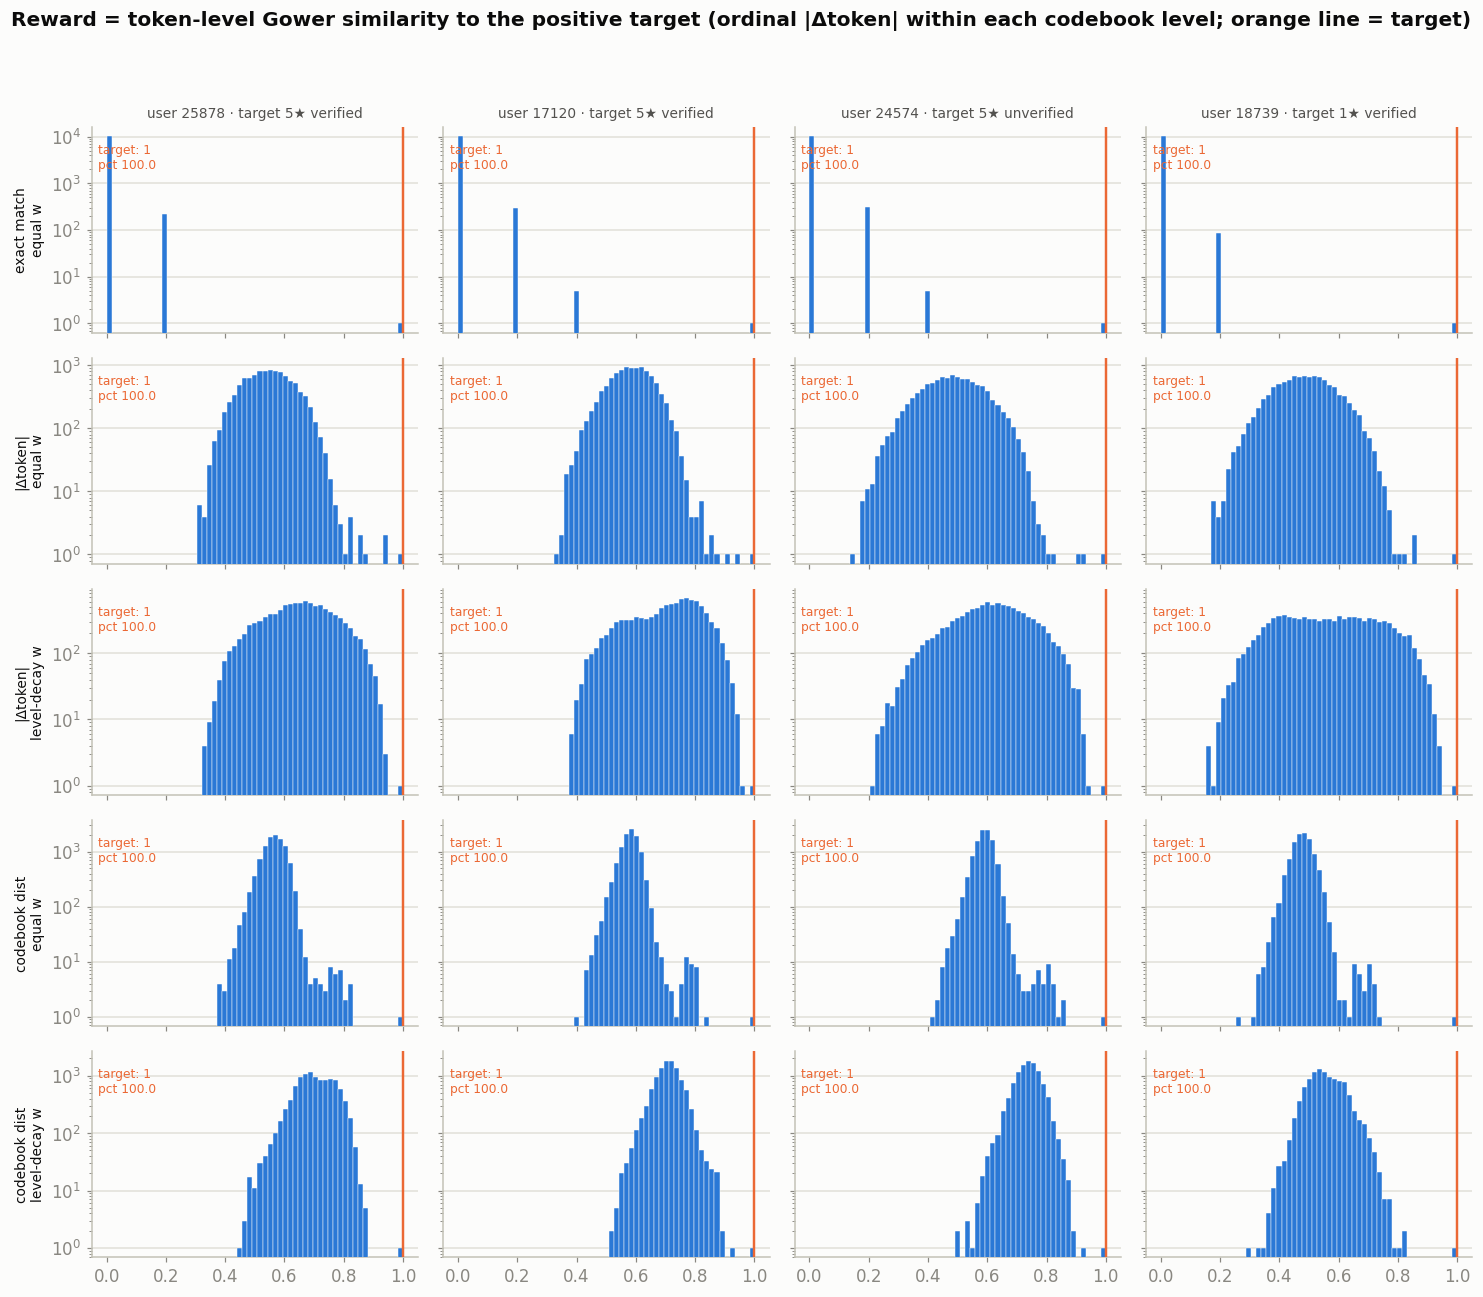

In [92]:
# --- Plot: reward = token-level Gower similarity, full catalog per user --------
variant_names = list(gower_rewards)
fig, axes = plt.subplots(
    len(variant_names), N_USERS,
    figsize=(3.4 * N_USERS, 2.4 * len(variant_names)),
    sharex=True, sharey="row",
)
bins = np.linspace(0, 1.001, 60)
for row, name in enumerate(variant_names):
    r = gower_rewards[name].numpy()
    for col in range(N_USERS):
        ax = axes[row, col]
        ax.hist(r[col], bins=bins, color=C_VERIFIED, edgecolor=SURFACE,
                linewidth=0.3, zorder=3)
        ax.set_yscale("log")
        tgt = float(r[col][is_positive[col].numpy()][0])
        pct = float((r[col] < tgt).mean() * 100)
        ax.axvline(tgt, color=C_UNVERIFIED, linewidth=1.6, zorder=4)
        ax.text(0.02, 0.92, f"target: {tgt:.3g}\npct {pct:.1f}",
                transform=ax.transAxes, ha="left", va="top",
                fontsize=8, color=C_UNVERIFIED)
        ax.grid(axis="x", visible=False)
        if row == 0:
            rt = batch["target_ratings"][col].item()
            ver = "verified" if bool(batch["target_verified_purchase"][col]) else "unverified"
            ax.set_title(f"user {int(batch['user_ids'][col])} · target {rt:.0f}★ {ver}",
                         fontsize=9, color=INK_2)
        if col == 0:
            ax.set_ylabel(name.replace(" · ", "\n"), fontsize=9, color=INK)

fig.suptitle(
    "Reward = token-level Gower similarity to the positive target "
    "(ordinal |Δtoken| within each codebook level; orange line = target)",
    fontweight="bold", x=0.01, ha="left",
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

In [93]:
# --- Which distance carries signal: |Δtoken| or codebook geometry? -------------
# Proxy check with the tuned SASRec item embeddings: mean cosine similarity of
# random item pairs, grouped (per RQ level) by (a) token index distance and
# (b) normalized codebook-vector distance. If a distance is meaningful, cosine
# should DECAY as it grows; a flat profile means the distance carries no
# information beyond the exact match.
E = torch.nn.functional.normalize(sasrec.item_embedding.weight.detach()[catalog], dim=1)
pair_rng = np.random.default_rng(0)
pairs = pair_rng.integers(0, N_CATALOG, size=(400_000, 2))
pairs = pairs[pairs[:, 0] != pairs[:, 1]]
cos = (E[pairs[:, 0]] * E[pairs[:, 1]]).sum(dim=1).numpy()
codes_cat = raw_codes[catalog]

IDX_BINS = [("|Δ| = 0", 0, 0), ("|Δ| = 1", 1, 1), ("|Δ| 2-5", 2, 5),
            ("|Δ| 6-20", 6, 20), ("|Δ| > 20", 21, 10**9)]
idx_rows, cb_rows = [], []
for level in range(N_RQ_LEVELS):
    a, b = codes_cat[pairs[:, 0], level], codes_cat[pairs[:, 1], level]
    d_idx = np.abs(a - b)
    idx_rows.append({
        "level": level + 1,
        **{lab: round(float(cos[(d_idx >= lo) & (d_idx <= hi)].mean()), 4)
           for lab, lo, hi in IDX_BINS},
    })
    d_cb = code_dist[level, a, b]
    nz = d_cb[d_cb > 0]
    qs = np.quantile(nz, [0.25, 0.5, 0.75])
    cb_bins = [("dist = 0", d_cb == 0), ("Q1 (closest)", (d_cb > 0) & (d_cb <= qs[0])),
               ("Q2", (d_cb > qs[0]) & (d_cb <= qs[1])), ("Q3", (d_cb > qs[1]) & (d_cb <= qs[2])),
               ("Q4 (farthest)", d_cb > qs[2])]
    cb_rows.append({
        "level": level + 1,
        **{lab: round(float(cos[m].mean()), 4) for lab, m in cb_bins},
    })
print(f"Mean SASRec-embedding cosine of item pairs (baseline = {cos.mean():.4f})")
print("\nby token INDEX distance:")
print(pd.DataFrame(idx_rows).to_string(index=False))
print("\nby CODEBOOK-vector distance (quartiles of nonzero distances):")
print(pd.DataFrame(cb_rows).to_string(index=False))

Mean SASRec-embedding cosine of item pairs (baseline = 0.0549)

by token INDEX distance:
 level  |Δ| = 0  |Δ| = 1  |Δ| 2-5  |Δ| 6-20  |Δ| > 20
     1   0.1336   0.0523   0.0546    0.0546    0.0544
     2   0.0585   0.0523   0.0543    0.0550    0.0549
     3   0.0515   0.0559   0.0562    0.0550    0.0548
     4   0.0566   0.0560   0.0544    0.0541    0.0550

by CODEBOOK-vector distance (quartiles of nonzero distances):
 level  dist = 0  Q1 (closest)     Q2     Q3  Q4 (farthest)
     1    0.1460        0.0746 0.0590 0.0493         0.0350
     2    0.0601        0.0520 0.0540 0.0557         0.0577
     3    0.0528        0.0541 0.0542 0.0552         0.0561
     4    0.0565        0.0545 0.0538 0.0545         0.0567


### Reading the token-Gower reward — index distance vs codebook geometry

- **All ordinal variants fix the sparsity, but are flat as rewards.** The delta
  landscape becomes a dense distribution, the target keeps similarity 1.0 and
  percentile 100 (by construction). Target/median contrast is ≈ 1.4–2.1 and
  `log R` std 0.11–0.24 (vs 1.79 for exact match) — differences average out
  across levels.
- **The index-distance assumption is refuted.** Sharing the *level-1* token is
  real signal (pair cosine 0.134 ≈ 2.4× the 0.055 random baseline), but pairs
  whose level-1 tokens differ by **just 1** sit at the baseline (0.052), and the
  profile is flat across every |Δ| > 0 bin. Codebook indices are nominal labels
  — index 51 is unrelated to index 50 — so the graded shoulder of the `|Δtoken|`
  rows is noise.
- **Codebook geometry, by contrast, is genuinely ordinal at level 1.** Mean pair
  cosine decays *monotonically* with codebook-vector distance:
  `0.146 (same code) → 0.075 (closest quartile) → 0.059 → 0.049 → 0.035
  (farthest)`. Pairs in the closest quartile are ~36% more similar than random,
  the farthest ~36% less — exactly the ordering the Gower numeric treatment
  needs. This is the option that works.
- **Levels 2–4 carry almost no item-level signal** — even at distance 0 their
  cosine (0.053–0.060) barely rises above the baseline: the residual levels
  refine reconstruction, not item identity. That is a strong empirical
  justification for the decaying level weights: effectively all usable
  similarity lives in level 1.
- **Verdict:** `codebook dist · level-decay w` is the defensible token-only
  similarity reward — graded by the quantizer's true latent geometry and
  dominated by the one level that carries signal. Caveats as before: it is
  target-conditioned (percentile 100 by construction) and mild
  (`log R` std ≈ 0.14), so if used as a TB terminal reward it likely needs
  sharpening (a power/exponential on the similarity) to give the loss a usable
  gradient; the collision-suffix level stays exact-match (it is a random
  tie-breaker with no geometry behind it).